# Supplementary Fig. 3f: modulation of the trough width of the second spike of bursts by the inter-spike interval (bursting units)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel f of Supplementary Fig. 3: width at half the amplitude of the negative peak (trough) of the first and second spikes of sequences of spikes of the bursting units of the simulated Neuropixels evoked regime, for five ranges of inter-spike intervals (ISIs). Source data and svg are saved in figures/8_source_data/supp_fig3f/.

**method (as in the paper's notebook supp_fig3_CDEF_burst_modulation_of_spike_revised.ipynb)**
* recording: `dataset/00_raw/recording_npx_evoked` (1 hour, 20 kHz) converted to int16, band-pass filtered (300-3000 Hz), common median referenced and whitened
* bursting units: ground truth units with at least one burst (at least 2 spikes with ISIs up to 21 ms and a duration of at least 20 ms)
* for each ISI range (0-21, 21-61, 61-101, 101-141 and 141-181 ms): the sequences of at least 2 spikes of a unit whose ISIs are all in the range and that last at least 20 ms; units with more than one sequence are kept; waveform (2.5 ms) of the first two spikes of each sequence on the site nearest to the unit, aligned on the negative peak; mean over sequences
* units whose mean waveform has a trough shallower than -7.5 uV (about 3 times the background noise) are dropped
* trough width: duration (ms) for which the mean waveform of a unit stays below half of its trough amplitude (`trough_width_halfmax`, resolution of one sample, 0.05 ms)
* boxplots over units of the trough widths of the first and second spikes; one-sided Wilcoxon signed-rank test (paired) that the second spike's trough is narrower than the first's

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt
import spikeinterface as si
import spikeinterface.preprocessing as spre
warnings.simplefilter(action="ignore")

# SET PATHS
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)
from src.nodes.validation.burst_spikes import find_bursts_isi, mean_waveforms_by_isi_range, trough_width_halfmax
import seaborn as sns
from scipy.stats import wilcoxon
REC_PATH = "dataset/00_raw/recording_npx_evoked"
GT_PATH = "dataset/00_raw/ground_truth_npx_evoked"

# PARAMETERS
FREQ_MIN, FREQ_MAX = 300, 3000      # band-pass filter (Hz)
MIN_SPIKES = 2                      # minimum number of spikes in a burst
ISI_THRESH_SEC = 0.021              # maximum inter-spike interval within a burst
MIN_SPIKES_SEQUENCE = 2             # minimum number of spikes in a sequence within an ISI range
NUM_SPIKES = 2                      # first spikes of each sequence
MIN_DURATION = 0.02                 # minimum duration of a sequence (seconds)
MIN_TROUGH_AMPLITUDE = -7.5         # minimum trough amplitude (uV), about 3 times the background noise
WINDOW_MS = 2.5                     # waveform duration
MIN_ISIS = [0, 0.021, 0.061, 0.101, 0.141]         # ISI ranges (seconds)
MAX_ISIS = [0.021, 0.061, 0.101, 0.141, 0.181]
ISI_LABELS = ["0-21", "21-61", "61-101", "101-141", "141-181"]

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Load the recording and the ground truth, find the bursting units

In [2]:
%%time

# recording: preprocessed lazily (only the traces around the spikes are computed)
Recording = si.load_extractor(REC_PATH)
Recording = spre.astype(Recording, "int16")
Recording = spre.bandpass_filter(Recording, freq_min=FREQ_MIN, freq_max=FREQ_MAX)
Recording = spre.common_reference(Recording, reference="global", operator="median")
Recording = spre.whiten(Recording, dtype="float32")
sfreq = Recording.get_sampling_frequency()
window_frames = int(WINDOW_MS / (1 / sfreq) / 1000)

# ground truth: bursting units
Gtruth = si.load_extractor(GT_PATH)
bursts = {u: find_bursts_isi(Gtruth.get_unit_spike_train(u) / sfreq, isi_threshold=ISI_THRESH_SEC, min_spikes=MIN_SPIKES) for u in Gtruth.unit_ids}
bursting_units = [u for u in Gtruth.unit_ids if len(bursts[u]) > 0]
print("number of bursting units:", len(bursting_units))

number of bursting units: 126
CPU times: user 14.3 s, sys: 259 ms, total: 14.6 s
Wall time: 13.8 s


## Trough widths of the first and second spikes for each ISI range (about 7 minutes)

In [3]:
%%time

rows = []
for min_isi, max_isi, label in zip(MIN_ISIS, MAX_ISIS, ISI_LABELS):
    mean_waves = mean_waveforms_by_isi_range(Recording, Gtruth, bursting_units, sfreq, min_isi, max_isi, MIN_SPIKES_SEQUENCE, window_frames, NUM_SPIKES, min_duration=MIN_DURATION, min_amplitude=MIN_TROUGH_AMPLITUDE)
    for unit, waves in mean_waves.items():
        for s, name in enumerate(["1st", "2nd"]):
            rows.append({"isi_range_ms": label, "unit": unit, "spike_rank": name, "trough_width_ms": trough_width_halfmax(waves[s], sfreq)})
    print(label, "ms:", len(mean_waves), "units")
df = pd.DataFrame(rows)

0-21 ms: 20 units


21-61 ms: 19 units


61-101 ms: 9 units


101-141 ms: 9 units


141-181 ms: 13 units
CPU times: user 24min 13s, sys: 3.82 s, total: 24min 17s
Wall time: 6min 4s


## Plot, same as the paper's panel d

In [4]:
def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"


def test_isi_range(d):
    """One-sided paired Wilcoxon signed-rank test that the trough of the 2nd spike is narrower than the 1st's"""
    first = d[d["spike_rank"] == "1st"].set_index("unit")["trough_width_ms"]
    second = d[d["spike_rank"] == "2nd"].set_index("unit")["trough_width_ms"].loc[first.index]
    z, p = wilcoxon(first, y=second, zero_method="wilcox", correction=False, alternative="greater")
    return len(first), z, p


def plot_source_data(df: pd.DataFrame):
    """Boxplots of the trough widths of the first (black) and second (red) spikes of sequences of the bursting units, by range of ISI"""

    fig, ax = plt.subplots(1, len(ISI_LABELS), figsize=(3, 2))
    for i, label in enumerate(ISI_LABELS):
        d = df[df["isi_range_ms"] == label]
        sns.boxplot(ax=ax[i], data=d, x="spike_rank", y="trough_width_ms", notch=True, palette=["k", "r"], width=0.4, linewidth=0.5, flierprops={"marker": ".", "markersize": 3})
        ax[i].spines[["top", "right"]].set_visible(False)
        ax[i].spines["bottom"].set_position(("axes", -0.05))
        ax[i].spines["left"].set_position(("axes", -0.05))
        ax[i].set_xlabel("")
        ax[i].set_ylabel("")
        ax[i].set_title(label, fontsize=6, pad=2)
        if i > 0:
            ax[i].set_yticks([])
            ax[i].spines["left"].set_visible(False)

    ax[0].set_ylabel("Trough widths ($\\mu V$)")      # unit as printed in the paper, widths are in ms
    ax[len(ISI_LABELS) // 2].set_xlabel("Spike order within burst")
    marks = [stars(test_isi_range(df[df["isi_range_ms"] == l])[2]) for l in ISI_LABELS]
    fig.text(0.52, 0.98, "All ns" if set(marks) == {"ns"} else " ".join(marks), ha="center", va="bottom", fontsize=6)
    fig.suptitle("Bursting units' ISI (ms)", fontsize=6.5, fontweight="bold", y=1.12)
    plt.subplots_adjust(wspace=0.4)

    return fig

## Plot and save the figure and the source data

,isi_range_ms,n_units,wilcoxon_signed_rank_z,p_one_sided,significance
0,0-21,20,57.5,0.197924,ns
1,21-61,19,5.0,0.938644,ns
2,61-101,9,4.5,0.207108,ns
3,101-141,9,6.0,0.352728,ns
4,141-181,13,20.5,0.129820,ns


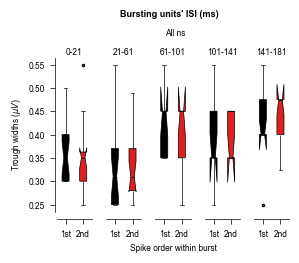

In [5]:
fig = plot_source_data(df)
os.makedirs("figures/8_source_data/supp_fig3f", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig3f/supp_fig3f.svg", bbox_inches="tight", **savefig_cfg)

# statistics of each panel
stats = pd.DataFrame([dict(isi_range_ms=l, n_units=n, wilcoxon_signed_rank_z=z, p_one_sided=p, significance=stars(p)) for l in ISI_LABELS for n, z, p in [test_isi_range(df[df["isi_range_ms"] == l])]])
display(stats)
with pd.ExcelWriter("figures/8_source_data/supp_fig3f/supp_fig3f.xlsx") as writer:
    df.to_excel(writer, sheet_name="trough_widths", index=False)
    stats.to_excel(writer, sheet_name="statistics", index=False)

## Check: replot from the saved source data

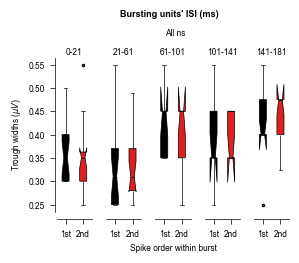

In [6]:
df = pd.read_excel("figures/8_source_data/supp_fig3f/supp_fig3f.xlsx", sheet_name="trough_widths", dtype={"unit": str})
fig = plot_source_data(df)